# Perceptron: From Scratch

This notebook explains and demonstrates the perceptron implementation in `perceptron.py`.

## Learning goals
- Understand the linear score and binary prediction rule.
- Understand how weight and bias updates correct misclassified samples.
- Train the implementation on NAND, a 2D CSV dataset, and breast cancer data.
- Visualize the learned decision boundary.

## 1. How the perceptron works

For an input feature vector $x$, the perceptron computes

$$
+    s(x) = W \cdot x + b
+    $$

where $W$ is the weight vector and $b$ is the bias. The implementation predicts class 1 when $s(x) > 0$, and class 0 otherwise.

During fitting, labels $y \in \{0,1\}$ are converted to signed labels $y_i \in \{-1,+1\}$. If a sample is incorrect or exactly on the boundary, the update rule is:

$$
+    W \leftarrow W + \alpha y_i x_i, \qquad b \leftarrow b + \alpha y_i
+    $$

Here, $\alpha=0.1$ is the learning rate. The update moves the decision boundary toward a correct classification.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the project parent to Python's import path when the notebook runs from
# the perceptron directory or its parent.
cwd = Path.cwd()
project_parent = cwd.parent if cwd.name == "perceptron" else cwd
sys.path.insert(0, str(project_parent))

from perceptron.perceptron import Perceptron

print("Perceptron implementation loaded successfully.")

Perceptron implementation loaded successfully.


## 2. Implementation walkthrough

- `__init__` stores the number of training passes, called epochs.
- `fit` initializes weights and bias, converts labels to signed values, and loops over every training sample.
- `predict` calculates $W \cdot X + b$ and uses a threshold of zero.

The perceptron is a linear classifier: it can learn linearly separable datasets. It does not need to use a hidden layer or a nonlinear activation function.

## 3. NAND experiment

NAND is true except when both inputs are 1:

| $x_1$ | $x_2$ | $y$ |
|---:|---:|---:|
| 0 | 0 | 1 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

In [2]:
X_nand = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_nand = np.array([1, 1, 1, 0])

nand_model = Perceptron()
nand_model.fit(X_nand, y_nand)

new_data = np.array([[1, 0], [1, 1], [0, 0]])
predictions = nand_model.predict(new_data)

print("Predictions:", predictions)
print("Learned weights:", nand_model.W)
print("Learned bias:", nand_model.b)

Predictions: [1 0 1]
Learned weights: [-0.2 -0.1]
Learned bias: 0.20000000000000004


## 4. 2D dataset

The labels can be visualized in a two-dimensional feature space. The black decision line represents

$$
+    W_1 x_1 + W_2 x_2 + b = 0
+    $$

Solving for $x_2$ gives

$$
+    x_2 = -\frac{W_1}{W_2}x_1 - \frac{b}{W_2}
+    $$

In [3]:
data_path = Path(r"C:\Scripts\projects\ai-engineering-projects\perceptron\data\data.csv")
df = pd.read_csv(data_path)

X = df[["x1", "x2"]].to_numpy()
y = df["label"].to_numpy()

model = Perceptron()
model.fit(X, y)

print("Weights:", model.W)
print("Bias:", model.b)
print("Training accuracy:", np.mean(model.predict(X) == y))

Weights: [-0.71373  0.53794]
Bias: 0.1
Training accuracy: 1.0


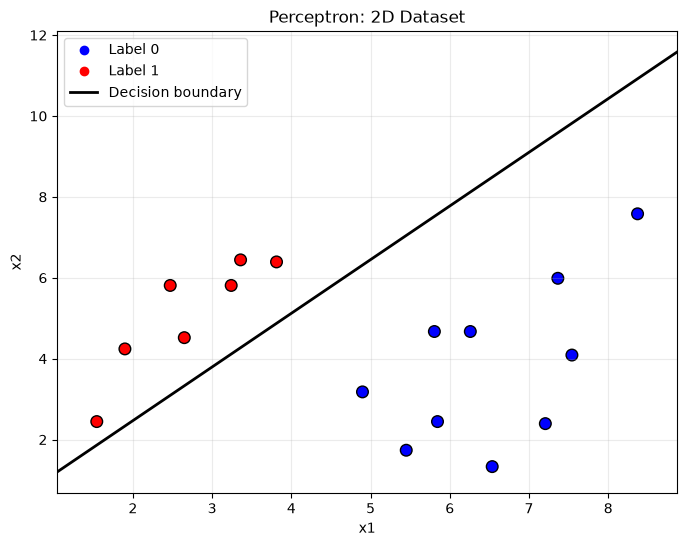

Test predictions: [1 0 1 0]


In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolor="k", s=70)

x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
x1_values = np.linspace(x1_min, x1_max, 200)

if abs(model.W[1]) > 1e-12:
    x2_values = -(model.W[0] * x1_values + model.b) / model.W[1]
    ax.plot(x1_values, x2_values, color="black", linewidth=2, label="Decision boundary")

ax.set(xlim=(x1_min, x1_max), xlabel="x1", ylabel="x2", title="Perceptron: 2D Dataset")
handles, labels = scatter.legend_elements()
ax.legend(handles=handles + ax.lines, labels=[f"Label {label}" for label in labels] + ["Decision boundary"])
ax.grid(alpha=0.25)
plt.show()

test_points = np.array([[4.4441, 6.8725], [8.5676, 4.6457],
                        [3.6747, 6.7966], [8.1676, 4.6457]])
print("Test predictions:", model.predict(test_points))

## 5. Real dataset: breast cancer classification

The breast cancer dataset has 30 numeric features. It is important to standardize features before training because features with large numeric ranges can dominate the perceptron's updates.

Standardization transforms each feature using

$$
+    z = \frac{x - \mu}{\sigma}
+    $$

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_real, y_real = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X_real, y_real, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

real_model = Perceptron(epochs=50)
real_model.fit(X_train, y_train)

y_pred = real_model.predict(X_test)
accuracy = np.mean(y_pred == y_test)
print(f"Test accuracy: {accuracy:.3f}")

Test accuracy: 0.956


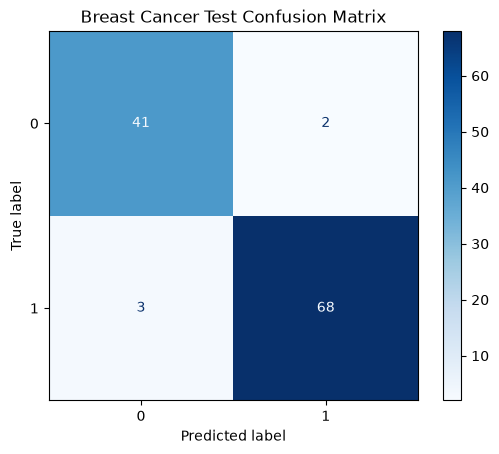

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Breast Cancer Test Confusion Matrix")
plt.show()

## 6. Conclusion

The perceptron is a simple online linear classifier. It works by repeatedly checking whether each sample satisfies $y_i(W \cdot x_i + b) > 0$. When it does not, it updates the weights and bias.

### Exercises
1. Change the learning rate by extending `Perceptron` and compare convergence.
2. Try the model without standardizing the breast cancer features.
3. Try XOR. Why does a single perceptron fail?
4. Plot the 2D data after several or 1000 epochs. Does the boundary change?
5. Add an explicit check for convergence instead of updating for every epoch.